# LAB 2 for CS4243: Perspective-Aware Virtual Advertisement Overlay
## Notebook 2 — Board localisation, optical flow, temporal variants, and failure monitoring
> **Introduction.** This notebook completes **Stage 1 (Localise)** in `overlaylab/localisation.py` and develops
> **Stage 2 (Track)** in `overlaylab/temporal.py`. Thresholds are chosen on the **validation** annotated frames of
> the common clip (even annotation index), frozen into `outputs/thresholds.json`, and only then reported on the
> **test** frames of the common clip and on each Stage's two stress clips (`python -m overlaylab.report` builds those
> tables from the finished runs). The cell marked **COMPARISON** is the only place where
> `cv2.calcOpticalFlowPyrLK` / `cv2.goodFeaturesToTrack` may appear. Cells marked **REQUIRED** must be completed.

## 1. Imports and reproducible configuration

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
import cv2

from overlaylab import data, metrics, visualize as viz
from overlaylab import supplied as sp
from overlaylab.config import notebook_config, replace
from overlaylab.localisation import localise_board, overlay_frame, evaluate_audit_frames
from overlaylab.temporal import lk_flow, track_board, failure_monitor, TrackInit
from overlaylab.geometry import ransac_homography, dlt_homography, transfer_points
from overlaylab import synthetic as syn
import json

from overlaylab.config import PipelineConfig
stage1 = ROOT / "outputs" / "stage1_settings.json"
config = PipelineConfig.from_json(stage1.read_text()) if stage1.exists() else notebook_config()
config.resize_width = data.NOTEBOOK_WIDTH
indices, frames, factor = data.load_notebook_subset()
reference_full = data.load_reference()
reference = sp.resize_width(reference_full, int(round(reference_full.shape[1] * factor)))
config.localisation.warp.reference_shape = reference.shape[:2]
artwork = data.load_artwork("ad")
gt_val = data.subset_gt_corners(indices, factor, "validation"); gt_test = data.subset_gt_corners(indices, factor, "test")
by_index = {i: frames[indices.index(i)] for i in indices}
print(len(frames), "subset frames;", len(gt_val), "validation and", len(gt_test), "test annotated frames")

63 subset frames; 13 validation and 13 test annotated frames


## 2. Stage 1 Localise — localise the board on the validation frames (REQUIRED)
Run `evaluate_audit_frames` on the validation frames, look at the corner-error distribution, **choose the success
threshold**, and freeze it. Choose detector, descriptor, matcher, RANSAC, flow, reinitialisation and monitor settings on validation/synthetic data before running test/stress cells. Record those choices in `config` here. For final native-resolution settings, use only full-resolution validation frames; the later preview cells are fixed-setting diagnostics.

frame    0: error   0.28%  matches  149  inliers  146  ratio 0.98  residual 0.61px  status True
frame   32: error   0.35%  matches  100  inliers   98  ratio 0.98  residual 0.66px  status True
frame   80: error   0.44%  matches   72  inliers   71  ratio 0.99  residual 0.69px  status True
frame  112: error   0.40%  matches  135  inliers  131  ratio 0.97  residual 0.64px  status True
frame  144: error   0.82%  matches   78  inliers   77  ratio 0.99  residual 0.62px  status True
frame  176: error   0.43%  matches  127  inliers  126  ratio 0.99  residual 0.64px  status True
frame  208: error   0.54%  matches   89  inliers   85  ratio 0.96  residual 0.66px  status True
frame  240: error   0.49%  matches   44  inliers   43  ratio 0.98  residual 0.77px  status True
frame  272: error   0.42%  matches   96  inliers   94  ratio 0.98  residual 0.65px  status True
frame  320: error   0.82%  matches   90  inliers   88  ratio 0.98  residual 0.66px  status True
frame  384: error   0.56%  matches  109 

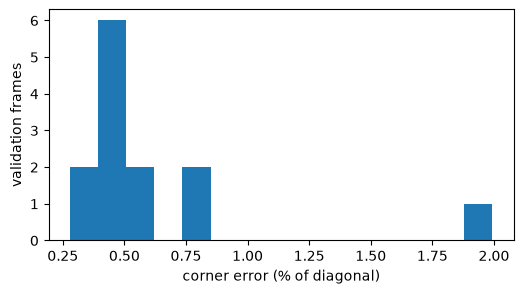

validation p90: 0.008211612261043218 threshold rule: p90 rounded up to 1% frozen threshold: 0.01
frozen success threshold: 0.01


In [2]:
val = evaluate_audit_frames(reference, {i: by_index[i] for i in gt_val}, gt_val, config.localisation)
for f, r in val["per_frame"].items():
    print(f"frame {f:4d}: error {r['error']*100:6.2f}%  matches {r['n_matches']:4d}  inliers {r['n_inliers']:4d}  ratio {r['inlier_ratio']:.2f}  residual {r['median_residual']:.2f}px  status {r['status']}")
errs = np.array([r["error"] for r in val["per_frame"].values()])
plt.figure(figsize=(6, 3)); plt.hist(errs[np.isfinite(errs)] * 100, bins=15); plt.xlabel("corner error (% of diagonal)"); plt.ylabel("validation frames"); plt.show()

# Choose the 90th-percentile validation error, rounded up to the next 1% step.
finite_val_errors = errs[np.isfinite(errs)]
if len(finite_val_errors) == 0:
    raise RuntimeError("No successful validation localisations; fix Stage 1 before freezing a threshold")
config.localisation.success_threshold = float(np.ceil(np.quantile(finite_val_errors, 0.90) * 100.0) / 100.0)
print("validation p90:", float(np.quantile(finite_val_errors, 0.90)),
      "threshold rule: p90 rounded up to 1%", "frozen threshold:", config.localisation.success_threshold)
Path(ROOT / "outputs").mkdir(exist_ok=True)
(ROOT / "outputs" / "thresholds.json").write_text(json.dumps(config.thresholds(), indent=2))   # full algorithm configuration; processing width/reference shape are set per run
print("frozen success threshold:", config.localisation.success_threshold)

## 3. Stage 1 Localise — report on the test frames (REQUIRED)
With the threshold frozen, report median / 90th-percentile error, the success fraction, inliers per frame, and the two worst
cases (state explicitly if they pass the frozen threshold) with the match visualisation, residual histogram and projected quadrilateral. This is the common-clip (test)
row of the Stage 1 stress table at the notebook resolution; the full-resolution table, including the viewpoint and
scale rows, is generated by `python -m overlaylab.report` with the frozen configuration (section 10).

test summary: {'n': 13, 'median': 0.0052, 'p90': 0.0071, 'success': 0.9231, 'failed': 0}


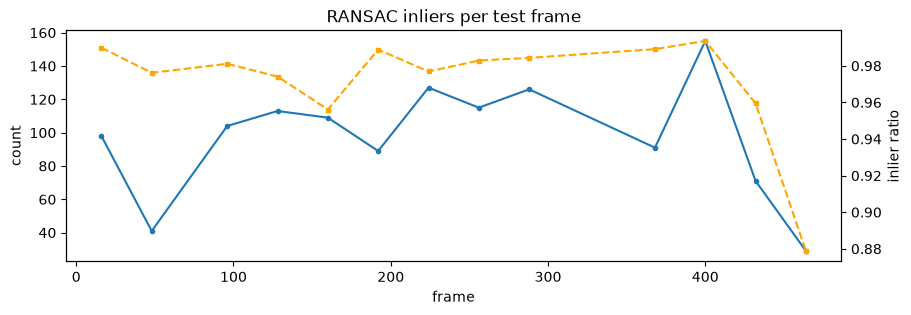

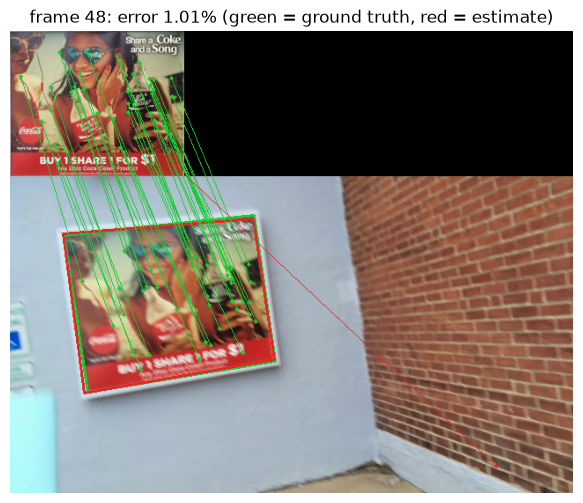

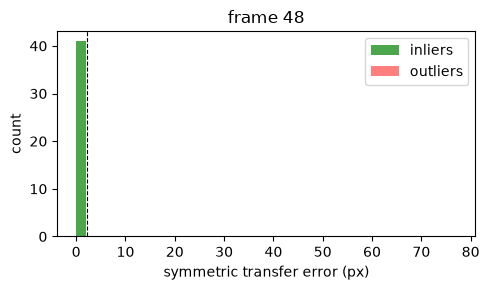

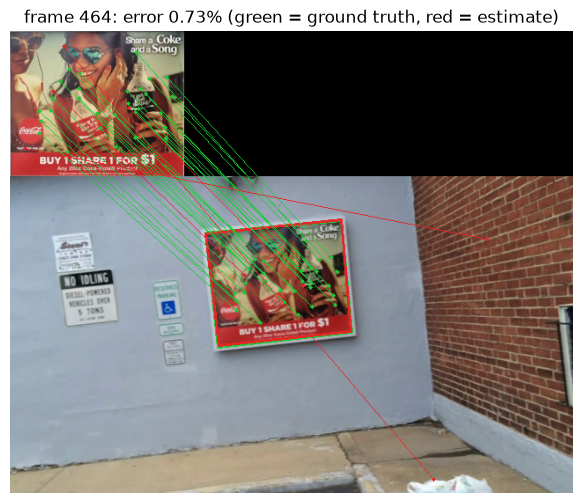

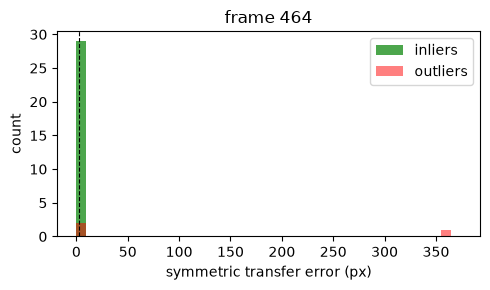

In [3]:
test = evaluate_audit_frames(reference, {i: by_index[i] for i in gt_test}, gt_test, config.localisation)
print("test summary:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in test["summary"].items()})
fr = sorted(test["per_frame"]); inl = [test["per_frame"][f]["n_inliers"] for f in fr]; rat = [test["per_frame"][f]["inlier_ratio"] for f in fr]
fig, ax = plt.subplots(figsize=(10, 3)); ax.plot(fr, inl, "o-", ms=3, label="inliers"); ax.set_xlabel("frame"); ax.set_ylabel("count")
ax2 = ax.twinx(); ax2.plot(fr, rat, "s--", ms=3, color="orange", label="ratio"); ax2.set_ylabel("inlier ratio"); ax.set_title("RANSAC inliers per test frame"); plt.show()

# Show the two worst common-clip test frames with matches, residuals, and estimated/ground-truth quads.
worst = sorted(fr, key=lambda f: -test["per_frame"][f]["error"])[:2]
for f in worst:
    H, corners, pairs, inliers, diag = localise_board(reference, by_index[f], config.localisation)
    plt.figure(figsize=(12, 6)); plt.imshow(viz.draw_matches(reference, viz.draw_quad(viz.draw_quad(by_index[f], gt_test[f], viz.GREEN), corners, viz.RED), diag["keypoints_ref"], diag["keypoints_frame"], pairs, inliers)); plt.axis("off")
    plt.title(f"frame {f}: error {test['per_frame'][f]['error']*100:.2f}% (green = ground truth, red = estimate)"); plt.show()
    if len(diag["residuals"]): viz.plot_residual_histogram(diag["residuals"], inliers, config.localisation.ransac.threshold, f"frame {f}"); plt.show()

## 4. RANSAC versus a least-squares fit to all ratio-test matches
Same matches, same settings, only the estimator changes.

In [4]:
rows = []
for f in sorted(gt_test):
    H, corners, pairs, inliers, diag = localise_board(reference, by_index[f], config.localisation)
    src = diag["keypoints_ref"][pairs[:, 0]]; dst = diag["keypoints_frame"][pairs[:, 1]]
    H_ls, _, ok = dlt_homography(src, dst) if len(pairs) >= 4 else (None, None, False)
    e_ls = metrics.corner_error(transfer_points(H_ls, sp.rect_corners(reference.shape[1], reference.shape[0])), gt_test[f]) if ok else float("inf")
    rows.append((f, test["per_frame"][f]["error"], e_ls))
print(f"{'frame':>5s} {'RANSAC':>8s} {'least-squares':>14s}")
for f, a, b in rows: print(f"{f:5d} {a*100:7.2f}% {b*100:13.2f}%")

frame   RANSAC  least-squares
   16    0.60%          0.57%
   48    1.01%         79.72%
   96    0.54%          1.97%
  128    0.41%          3.84%
  160    0.52%          0.52%
  192    0.65%          2.62%
  224    0.35%          0.77%
  256    0.46%          0.62%
  288    0.37%          0.35%
  368    0.60%          0.47%
  400    0.52%          0.45%
  432    0.42%          0.37%
  464    0.73%        203.86%


## 5. The viewpoint clip — affine versus homography (REQUIRED)
Every clip other than the common clip isolates one capture factor and is named by it (`data.clip_factor`); each Stage
reports on its two stress clips, `data.stress_clips(stage)`. On the **viewpoint** clip the camera rotates *and* moves
around the poster, so the board's image is a general quadrilateral and a 6-parameter affine model cannot place the
artwork. Fit an affine transformation by least squares to the *same* inlier correspondences that RANSAC selected and
compare the corner error of both models on every annotated frame (the same comparison fills the *affine* column of the
Stage 1 stress table). Thresholds stay frozen: nothing is tuned here.

stress clips per Stage: {1: {'viewpoint': 'coke_perspective', 'scale': 'coke_scale'}, 2: {'blur': 'coke_blur', 'exit': 'coke_out_of_view'}, 3: {'viewpoint': 'coke_perspective', 'combined': 'coke_unconstrained'}}
viewpoint  coke_perspective   scale [0.584, 1.067]  rotation [-21.0, 36.5] deg  keystone 1.586  affine residual of the GT quads 9.8%
scale      coke_scale         scale [0.285, 1.001]  rotation [-7.2, 0.7] deg  keystone 1.058  affine residual of the GT quads 1.6%
blur       coke_blur          scale [0.81, 1.173]  rotation [-18.3, 8.5] deg  keystone 1.16  affine residual of the GT quads 2.4%
exit       coke_out_of_view   scale [0.945, 1.217]  rotation [-9.1, 0.8] deg  keystone 1.178  affine residual of the GT quads 2.4%
combined   coke_unconstrained scale [0.755, 1.331]  rotation [-78.6, 80.3] deg  keystone 1.563  affine residual of the GT quads 9.3%

coke_perspective: frame  homography   affine
    0       0.34%    0.83%
   16       0.45%    0.84%
   32       0.47%    1.39%
   

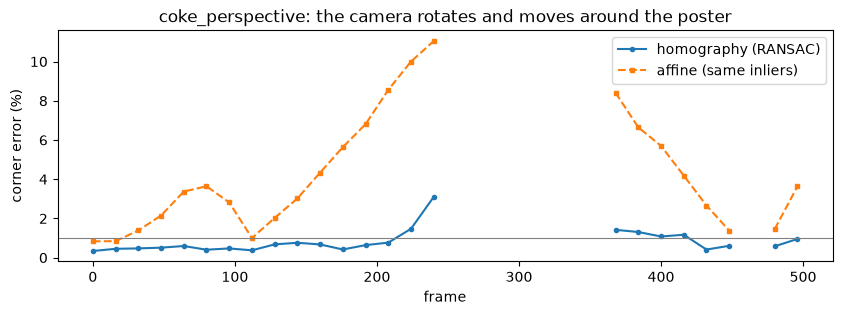

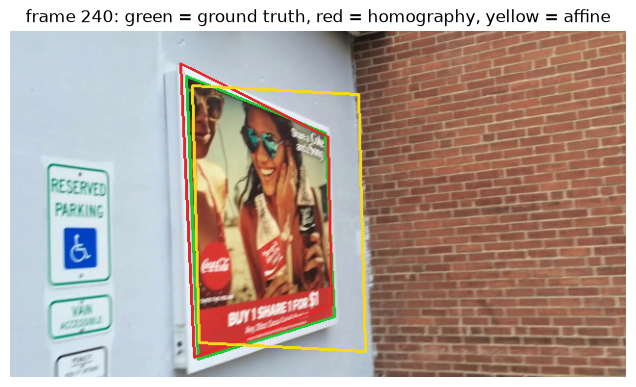


frame  keystone  homography_error  affine_error
    0     0.030             0.34%          0.83%
   16     0.036             0.45%          0.84%
   32     0.052             0.47%          1.39%
   48     0.077             0.51%          2.15%
   64     0.138             0.59%          3.37%
   80     0.147             0.41%          3.64%
   96     0.112             0.47%          2.82%
  112     0.045             0.37%          1.00%
  128     0.090             0.68%          2.03%
  144     0.136             0.76%          3.02%
  160     0.179             0.67%          4.34%
  176     0.245             0.42%          5.64%
  192     0.297             0.64%          6.81%
  208     0.358             0.77%          8.56%
  224     0.398             1.47%         10.00%
  240     0.422             3.10%         11.05%
  256     0.441              inf%           inf%
  272     0.441              inf%           inf%
  288     0.435              inf%           inf%
  304     0.437     

In [5]:
print("stress clips per Stage:", data.stress_clips())
for cid in data.stress_clip_ids():
    g = sp.read_json(data.DATASET_SUMMARY)["diagnostic_clips"][cid]["geometry"]
    print(f"{data.clip_factor(cid):10s} {cid:18s} scale {g['scale_range']}  rotation {g['in_plane_rotation_deg']} deg  keystone {g['max_keystone']}  affine residual of the GT quads {g['max_affine_residual']*100:.1f}%")
from overlaylab.report import affine_from_points      # least-squares 6-parameter affine map as a 3 x 3 matrix

lvl2 = data.stress_clips(1)["viewpoint"]
video_l2, _ = data.clip_paths(lvl2)                                            # same poster, same reference image
gt_l2 = data.load_diagnostic_corners(lvl2, scale=factor)
frames_l2 = {i: fr for i, fr in sp.iter_video(video_l2, step=data.GT_STRIDE, width=frames[0].shape[1]) if i in gt_l2}
ref_rect = sp.rect_corners(reference.shape[1], reference.shape[0])
rows_l2 = {}
for f in sorted(frames_l2):
    H, corners, pairs, inliers, diag = localise_board(reference, frames_l2[f], config.localisation)
    if not diag["status"] or inliers.sum() < 4:
        rows_l2[f] = (float("inf"), float("inf"), None, None); continue
    src = diag["keypoints_ref"][pairs[inliers, 0]]; dst = diag["keypoints_frame"][pairs[inliers, 1]]
    H_aff = affine_from_points(src, dst)
    rows_l2[f] = (metrics.corner_error(corners, gt_l2[f]), metrics.corner_error(transfer_points(H_aff, ref_rect), gt_l2[f]), corners, transfer_points(H_aff, ref_rect))
print(f"\n{lvl2}: {'frame':>5s} {'homography':>11s} {'affine':>8s}")
for f, (eh, ea, *_) in rows_l2.items(): print(f"{f:5d} {eh*100:10.2f}% {ea*100:7.2f}%")
eh = np.array([r[0] for r in rows_l2.values()]); ea = np.array([r[1] for r in rows_l2.values()]); ok = np.isfinite(eh) & np.isfinite(ea)
print(f"median corner error: homography {np.median(eh[ok])*100:.2f}%  affine {np.median(ea[ok])*100:.2f}%   success@{config.localisation.success_threshold:.0%}: {np.mean(eh < config.localisation.success_threshold):.0%} vs {np.mean(ea < config.localisation.success_threshold):.0%}")
fr_l2 = sorted(rows_l2); plt.figure(figsize=(10, 3)); plt.plot(fr_l2, eh * 100, "o-", ms=3, label="homography (RANSAC)"); plt.plot(fr_l2, ea * 100, "s--", ms=3, label="affine (same inliers)")
plt.axhline(config.localisation.success_threshold * 100, color="gray", lw=.8); plt.xlabel("frame"); plt.ylabel("corner error (%)"); plt.title(f"{lvl2}: the camera rotates and moves around the poster"); plt.legend(); plt.show()
f = max((f for f in rows_l2 if rows_l2[f][2] is not None), key=lambda f: rows_l2[f][1])
img = viz.draw_quad(viz.draw_quad(viz.draw_quad(frames_l2[f], gt_l2[f], viz.GREEN), rows_l2[f][2], viz.RED), rows_l2[f][3], viz.YELLOW)
plt.figure(figsize=(8, 4.5)); plt.imshow(img); plt.axis("off"); plt.title(f"frame {f}: green = ground truth, red = homography, yellow = affine"); plt.show()
# Compare the same-inlier estimator errors with an opposite-edge keystone measure.
def keystone_ratio(quad):
    q = np.asarray(quad, dtype=float)
    top = np.linalg.norm(q[1] - q[0]); bottom = np.linalg.norm(q[2] - q[3])
    left = np.linalg.norm(q[3] - q[0]); right = np.linalg.norm(q[2] - q[1])
    return max(abs(top - bottom) / max((top + bottom) / 2, 1e-9),
               abs(left - right) / max((left + right) / 2, 1e-9))

print("\nframe  keystone  homography_error  affine_error")
for frame_id in sorted(rows_l2):
    e_h, e_a, _, _ = rows_l2[frame_id]
    print(f"{frame_id:5d}  {keystone_ratio(gt_l2[frame_id]):8.3f}  {e_h*100:15.2f}%  {e_a*100:12.2f}%")
print("Interpretation: camera orbit adds projective keystone; affine maps preserve parallel lines, while the homography models the planar projective mapping.")


## 6. COMPARISON — `cv2.warpPerspective`: single-frame overlay and the parallax question (**Question 2**)
Warp a *whole frame* with the board-fitted homography between two frames that include camera translation: the board aligns,
the background does not. Do it on the viewpoint clip, where the camera orbits the poster, and explain why the parallax outside
the board does not harm the overlay.

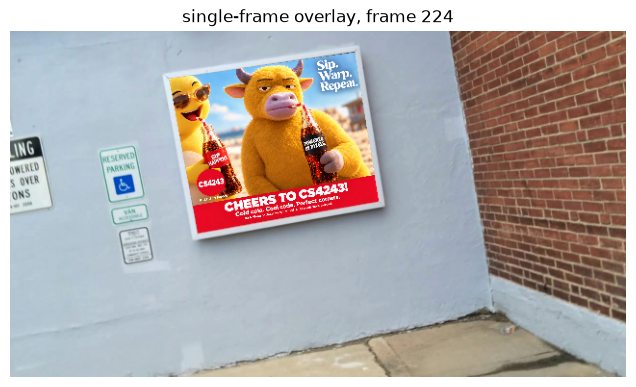

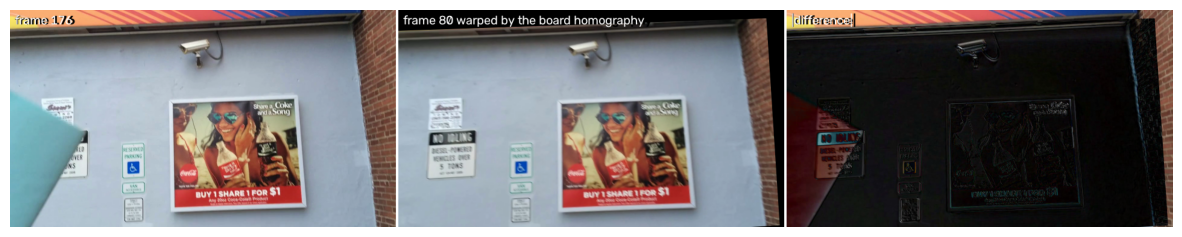

A viewpoint frame did not localise; choose a pair with valid homographies


In [6]:
f = sorted(gt_test)[len(gt_test) // 2]
H, corners, *_ = localise_board(reference, by_index[f], config.localisation)
plt.figure(figsize=(8, 4.5)); plt.imshow(overlay_frame(by_index[f], artwork, H, config.localisation)); plt.axis("off"); plt.title(f"single-frame overlay, frame {f}"); plt.show()
fa, fb = sorted(gt_val)[2], sorted(gt_val)[5]
Ha, *_ = localise_board(reference, by_index[fa], config.localisation); Hb, *_ = localise_board(reference, by_index[fb], config.localisation)
H_ab = Hb @ np.linalg.inv(Ha)                      # frame a -> frame b through the board plane
warped_a = cv2.warpPerspective(by_index[fa], H_ab.astype(np.float32), (frames[0].shape[1], frames[0].shape[0]))
plt.figure(figsize=(15, 4)); plt.imshow(viz.montage([viz.label(by_index[fb], f"frame {fb}"), viz.label(warped_a, f"frame {fa} warped by the board homography"), viz.label(np.abs(warped_a - by_index[fb]), "|difference|")], cols=3)); plt.axis("off"); plt.show()
# Warp a whole viewpoint frame through the board-plane homography. The board aligns; off-plane background shows parallax.
view_ids = sorted(frames_l2)
if len(view_ids) < 2:
    print("Need at least two annotated viewpoint frames for the parallax comparison")
else:
    pair = max(((a, b) for i, a in enumerate(view_ids) for b in view_ids[i + 1:]),
               key=lambda ab: np.linalg.norm(np.mean(gt_l2[ab[1]], axis=0) - np.mean(gt_l2[ab[0]], axis=0)))
    va, vb = pair
    Ha, *_ = localise_board(reference, frames_l2[va], config.localisation)
    Hb, *_ = localise_board(reference, frames_l2[vb], config.localisation)
    if Ha is None or Hb is None:
        print("A viewpoint frame did not localise; choose a pair with valid homographies")
    else:
        H_view = Hb @ np.linalg.inv(Ha)
        warped_view = cv2.warpPerspective(frames_l2[va], H_view.astype(np.float32),
                                          (frames[0].shape[1], frames[0].shape[0]))
        difference = np.abs(warped_view - frames_l2[vb])
        plt.figure(figsize=(15, 4))
        plt.imshow(viz.montage([viz.label(frames_l2[vb], f"viewpoint frame {vb}"),
                                viz.label(warped_view, f"frame {va} warped by board H"),
                                viz.label(difference, "absolute difference")], cols=3))
        plt.axis("off"); plt.show()


## 7. Stage 2 Track — Lucas–Kanade flow between consecutive frames
Consecutive full-rate frames (at 640 px) around the occlusion are loaded here so that the per-frame motion is small.
Inspect the eigenvalues of the structure tensor at the tracked points: points on the straight board edges have a small
$\lambda_2$ (aperture problem), points under the occluder violate brightness constancy (**Question 3**).

49 tracked points, 5 valid; median |flow| 26.99 px


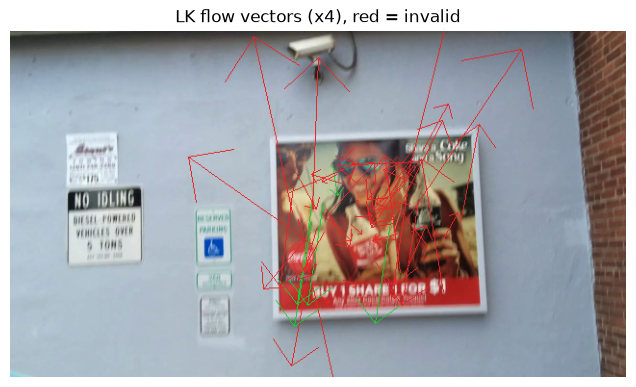

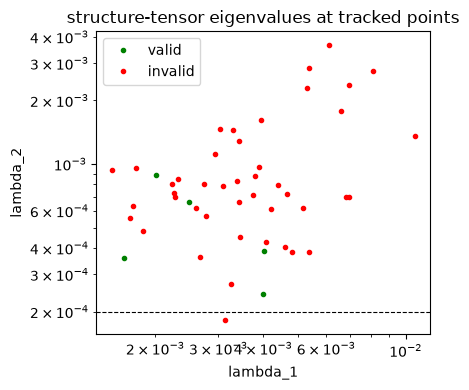

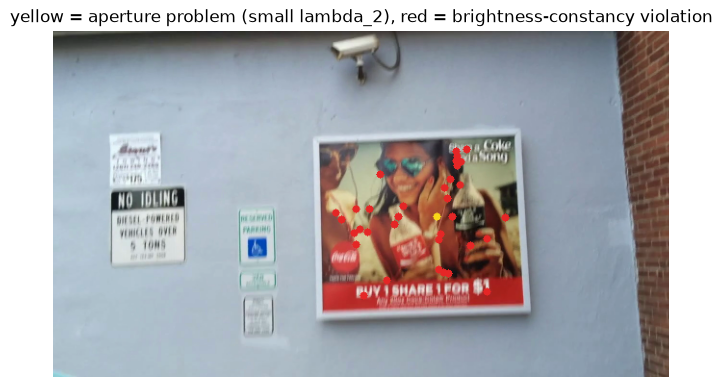

In [7]:
seg_idx, seg, _ = data.load_consecutive_frames(170, 240)
g0, g1 = sp.to_gray(seg[0]), sp.to_gray(seg[1])
H0, c0, pairs0, inl0, diag0 = localise_board(reference, seg[0], config.localisation)
pts = diag0["keypoints_frame"][pairs0[inl0, 1]]
d, eig, resid, valid = lk_flow(g0, g1, pts, config.track.flow)
print(f"{len(pts)} tracked points, {valid.sum()} valid; median |flow| {np.median(np.linalg.norm(d[valid], axis=1)):.2f} px")
plt.figure(figsize=(8, 4.5)); plt.imshow(viz.draw_flow(seg[0], pts, d, valid, scale=4)); plt.axis("off"); plt.title("LK flow vectors (x4), red = invalid"); plt.show()
viz.plot_eigenvalues(eig, valid, config.track.flow.min_eigenvalue, "structure-tensor eigenvalues at tracked points"); plt.show()
# where do the invalid points lie? edge-dominated (small lambda_2) versus brightness-constancy violations (large residual)
aperture = eig[:, 1] < config.track.flow.min_eigenvalue; residual_fail = resid > config.track.flow.max_residual
plt.figure(figsize=(8, 4.5)); plt.imshow(viz.draw_points(viz.draw_points(seg[0], pts[aperture], viz.YELLOW, 4), pts[residual_fail & ~aperture], viz.RED, 4)); plt.axis("off")
plt.title("yellow = aperture problem (small lambda_2), red = brightness-constancy violation"); plt.show()

### COMPARISON CELL — `cv2.calcOpticalFlowPyrLK` (the only cell where it is permitted)

In [8]:
p0 = pts.astype(np.float32).reshape(-1, 1, 2)
p1, st, err = cv2.calcOpticalFlowPyrLK(sp.to_uint8(g0), sp.to_uint8(g1), p0, None, winSize=(15, 15), maxLevel=2)
d_cv = (p1 - p0).reshape(-1, 2); both = valid & (st.ravel() == 1)
print(f"median |ours - cv2| over {both.sum()} points both consider valid: {np.median(np.linalg.norm(d[both] - d_cv[both], axis=1)):.3f} px")

median |ours - cv2| over 5 points both consider valid: 0.005 px


## 8. Stage 2 Track — the two temporal variants (REQUIRED)
Run both variants on the consecutive segment and compare jitter and drift against the interpolated ground truth. Then
plot the per-frame statistics your monitor consumes. Flicker (independent) versus drift (flow-assisted) is the first part
of **Question 3**.

independent    ok 64/70  reinits 64  jitter 2.24px  errors on annotated frames [0.43, 0.65, 0.54, 0.35]
flow_assisted  ok 66/70  reinits 7  jitter 3.41px  errors on annotated frames [0.59, 0.66, 3.03, 0.33]


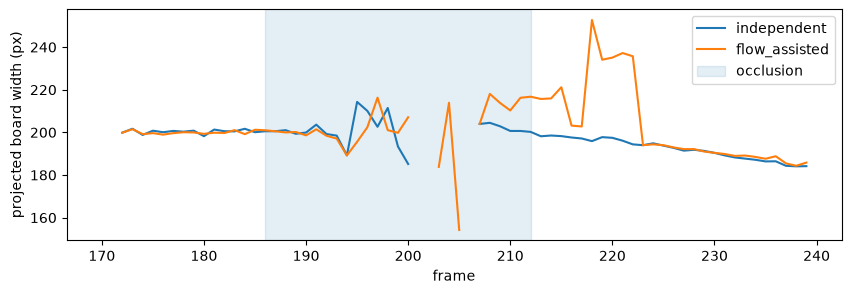

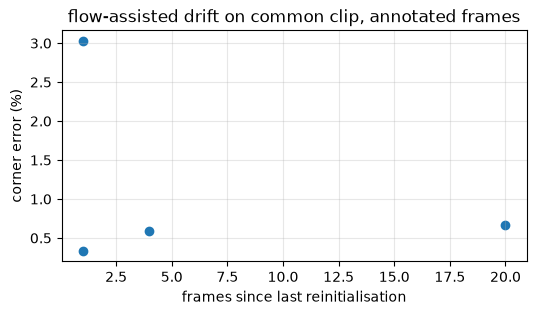

In [9]:
gt_all = data.load_gt_corners(scale=factor); gt_frames = sorted(gt_all); gt_list = [gt_all[f] for f in gt_frames]
results = {}
for variant in ("independent", "flow_assisted"):
    cfg = replace(config.track, variant=variant)
    results[variant] = track_board(seg, TrackInit(reference, config.localisation), cfg)
    res = results[variant]
    pred = {seg_idx[k]: res.corners[k] for k in range(len(seg_idx)) if res.status[k] == "ok"}
    errs = {f: metrics.corner_error(pred[f], gt_all[f]) for f in pred if f in gt_all}
    print(f"{variant:14s} ok {sum(s == 'ok' for s in res.status)}/{len(seg)}  reinits {len(res.reinit_frames)}  "
          f"jitter {metrics.jitter(pred, gt_frames, gt_list):.2f}px  errors on annotated frames {[round(e*100,2) for e in errs.values()]}")
fig, ax = plt.subplots(figsize=(10, 3))
for variant, res in results.items():
    ax.plot(seg_idx, [np.linalg.norm(c[1] - c[0]) if np.all(np.isfinite(c)) else np.nan for c in res.corners], label=variant)
occlusion_events = sp.read_json(data.DATASET_SUMMARY)["common_clip"]["events"]["occlusion"]   # [start, end] frame pairs
for k, (a, b) in enumerate(e for e in occlusion_events if e[1] >= seg_idx[0] and e[0] <= seg_idx[-1]):
    ax.axvspan(a, b, alpha=.12, color="tab:blue", label="occlusion" if k == 0 else None)
ax.set_xlabel("frame"); ax.set_ylabel("projected board width (px)"); ax.legend(); plt.show()

# YOUR CODE HERE — drift: corner error as a function of frames since the last reinitialisation (use metrics.drift)
# Plot flow-assisted corner error against frames since its most recent reference reinitialisation.
flow_result = results["flow_assisted"]
flow_pred = {seg_idx[k]: flow_result.corners[k] for k in range(len(seg_idx))
             if flow_result.status[k] == "ok"}
flow_errors = {f: metrics.corner_error(flow_pred[f], gt_all[f])
               for f in flow_pred if f in gt_all}
reinit_source_frames = [seg_idx[k] for k in flow_result.reinit_frames]
drift_points = metrics.drift(flow_errors, reinit_source_frames)
if drift_points:
    plt.figure(figsize=(6, 3))
    plt.scatter([d for d, _ in drift_points], [e * 100 for _, e in drift_points])
    plt.xlabel("frames since last reinitialisation"); plt.ylabel("corner error (%)")
    plt.title("flow-assisted drift on common clip, annotated frames"); plt.grid(alpha=.3); plt.show()
else:
    print("No annotated flow-assisted predictions available for the drift plot")


## 9. Failure monitor diagnostics (settings already frozen in section 2)
Do not retune from the test/stress plots. Use the synthetic stress sequences for events the common clip does not contain (whip-pan, illumination step, near-total
occlusion). Plot the statistics around each event, identify which fires first, and name the violated assumption.
**Question 3** asks the same on the **combined** clip (`data.stress_clips(3)["combined"]`, run by `run_pipeline --all`
for the Stage 3 table; then `viz.plot_monitor_timeline` on its `_stats.json`): which statistic fired first at the card
crossing (frames 210-222, 302-314) and at the fast rotation, and how the monitor separates occlusion from drift. The
**blur** and **exit** clips of the Stage 2 table show the other two failure modes (brightness constancy, board leaving the frame).

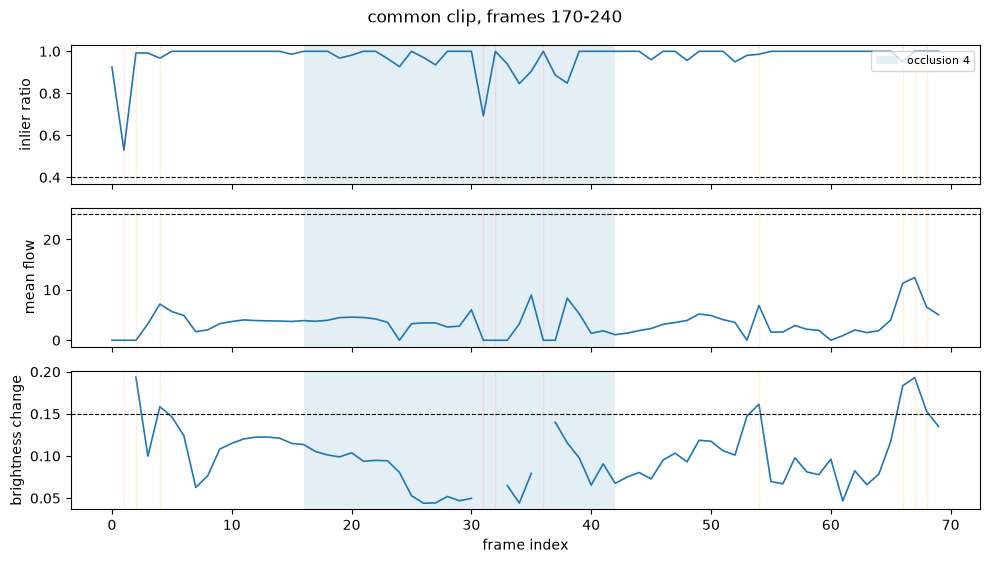

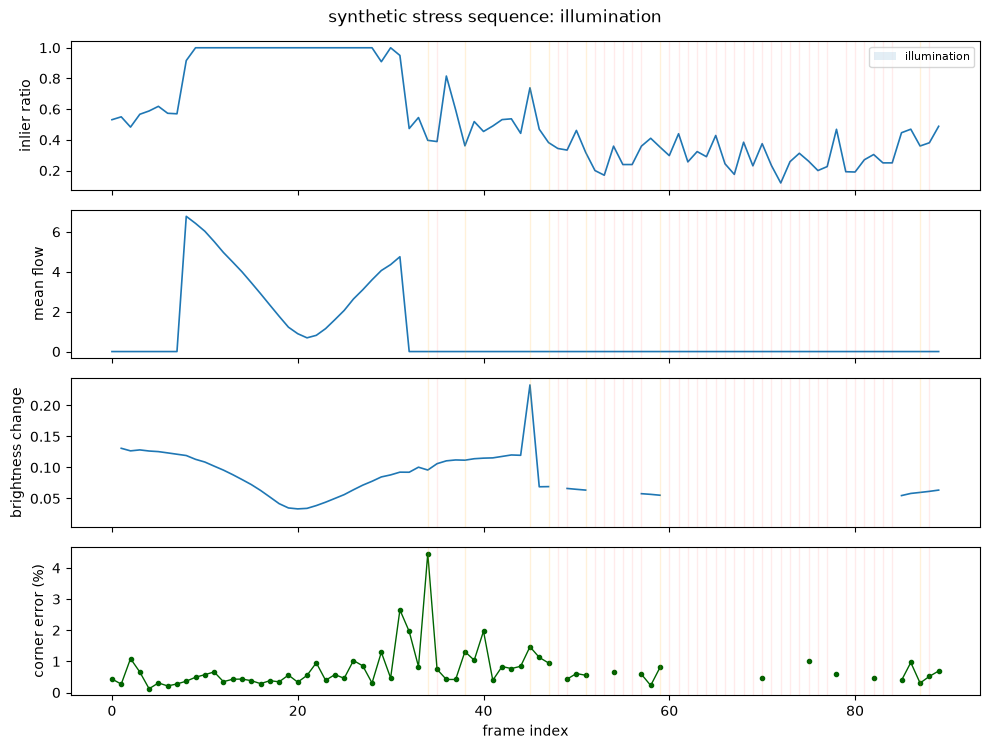

first non-OK flag: (34, ('REINIT', 'inlier_ratio'))
Frozen settings unchanged; these are diagnostic plots.


In [10]:
from overlaylab.synthetic import stress_specs, render_sequence
flags = failure_monitor(results["flow_assisted"].stats, config.track.monitor)
events_in_seg = {f"occlusion {k}": (a - seg_idx[0], b - seg_idx[0]) for k, (a, b) in enumerate(occlusion_events)
                 if b >= seg_idx[0] and a <= seg_idx[-1]}
viz.plot_monitor_timeline(results["flow_assisted"].stats, flags, events_in_seg,
                          thresholds={"inlier_ratio": config.track.monitor.min_inlier_ratio, "mean_flow": config.track.monitor.max_mean_flow,
                                      "brightness_change": config.track.monitor.max_brightness_change}, title="common clip, frames 170-240"); plt.show()
name = "illumination"   # try: "whip_pan", "near_total_occlusion", "exit", "long_track"
spec = stress_specs()[name]; seq = render_sequence(spec)
ref_syn = sp.resize_width(seq.board, 480); cfg_syn = replace(config.localisation, warp=replace(config.localisation.warp, reference_shape=ref_syn.shape[:2]))
res_syn = track_board(seq.frames, TrackInit(ref_syn, cfg_syn), replace(config.track, variant="flow_assisted"))
flags_syn = failure_monitor(res_syn.stats, config.track.monitor)
errs_syn = {i: metrics.corner_error(res_syn.corners[i], seq.corners[i]) for i in range(len(seq.frames))}
viz.plot_monitor_timeline(res_syn.stats, flags_syn, seq.events, errors=errs_syn, title=f"synthetic stress sequence: {name}"); plt.show()
print("first non-OK flag:", next(((i, f) for i, f in enumerate(flags_syn) if f[0] != "OK"), None))
assert json.loads((ROOT / "outputs" / "thresholds.json").read_text()) == config.thresholds(), "settings changed after freezing: choose settings on validation first, then rerun"
print("Frozen settings unchanged; these are diagnostic plots.")

## 10. The stress tables of Stages 1 and 2
After Notebook 3 has frozen the occlusion settings in `outputs/thresholds.json`, the full-resolution runs and the three stress tables are two commands, run from
`code/` in a terminal (about 30 minutes of compute for the eight videos; `--all` skips videos that already exist):

    python -m overlaylab.run_pipeline --all --thresholds outputs/thresholds.json
    python -m overlaylab.report

`report` runs `localise_board` on the annotated frames of the common clip (validation / test) and of the viewpoint and
scale clips for the Stage 1 table (including the affine column of section 5), reads the `_stats.json` of each run for the
Stage 2 table (common clip with both temporal variants, blur and exit clips with the flow-assisted one), and scores the
saved masks and the evaluator reports for the Stage 3 table. Paste `outputs/stress_tables.md` into the report and explain
the row each question points at. The cell below loads the tables once they exist.

In [11]:
tables = ROOT / "outputs" / "stress_tables.md"
print(tables.read_text() if tables.exists() else "run the two commands above first: outputs/stress_tables.md not found")
# Optional saved-run diagnostics for Stage 2 blur/exit and Stage 3 combined clips.
from overlaylab.pipelines import load_stats
clip_ids = {"blur": data.stress_clips(2)["blur"],
            "exit": data.stress_clips(2)["exit"],
            "combined": data.stress_clips(3)["combined"]}
for label, cid in clip_ids.items():
    stats_path = ROOT / "outputs" / "videos" / f"{cid}_flow_assisted_stats.json"
    if not stats_path.exists():
        print(f"{label} ({cid}): run the full pipeline first; {stats_path.name} is missing")
        continue
    saved = load_stats(stats_path)
    flags_saved = failure_monitor(saved["stats"], config.track.monitor)
    viz.plot_monitor_timeline(saved["stats"], flags_saved, title=f"{label} clip ({cid}), flow-assisted")
    ground_truth = (data.load_gt_corners(scale=1.0) if cid == "common_clip"
                    else data.load_diagnostic_corners(cid, scale=1.0))
    errors_saved = {f: metrics.corner_error(saved["corners"][f], q)
                    for f, q in ground_truth.items()
                    if f < len(saved["corners"]) and saved["status"][f] == "ok"}
    drift_saved = metrics.drift(errors_saved, saved["reinit_frames"])
    if drift_saved:
        plt.figure(figsize=(6, 3))
        plt.scatter([d for d, _ in drift_saved], [e * 100 for _, e in drift_saved])
        plt.xlabel("frames since last reinitialisation"); plt.ylabel("corner error (%)")
        plt.title(f"{label} ({cid}), flow-assisted drift"); plt.grid(alpha=.3); plt.show()


run the two commands above first: outputs/stress_tables.md not found
blur (coke_blur): run the full pipeline first; coke_blur_flow_assisted_stats.json is missing
exit (coke_out_of_view): run the full pipeline first; coke_out_of_view_flow_assisted_stats.json is missing
combined (coke_unconstrained): run the full pipeline first; coke_unconstrained_flow_assisted_stats.json is missing


## Reflection prompts
1. When does independent registration flicker, and when does the flow-assisted variant drift?
2. Which monitor statistic separates a physical occlusion from tracking drift, given that both lower the inlier ratio?
3. How would you reinitialise after the board re-enters the frame without using the ground truth?

## Reflection answers

1. When does independent registration flicker, and when does the flow-assisted variant drift?

- Independent mode registers each frame separately against the reference, so small changes in keypoint detection, matching, or the RANSAC inlier set can move the estimated corners from frame to frame. Flow-assisted mode propagates the previous inliers and is usually temporally smoother, but each flow estimate depends on the previous estimate; small motion errors can accumulate into drift. Reinitialising from the reference resets that accumulated error.

2. Which monitor statistic separates a physical occlusion from tracking drift, given that both lower the inlier ratio?

- A low inlier ratio alone does not distinguish them. A physical occluder changes the pixels inside the board and tends to raise `brightness_change` because brightness constancy fails. Tracking drift is more directly indicated by growing reprojection residual or corner displacement, and sometimes excessive mean flow. The monitor checks the inlier statistics first, so those measurements help interpret the cause after a low-consensus trigger. Confirm which trigger fired first by reading the saved combined-clip timeline after the pipeline run.

3. How would you reinitialise after the board re-enters the frame without using the ground truth 

- Use the monitor's `REINIT`/`HIDE` decision or a scheduled retry to run `localise_board` on the current frame using the reference image. Resume tracking only after RANSAC finds a valid homography with enough inliers; then seed LK from those reference-to-frame inlier pairs. This uses image evidence and the reference, not ground-truth corners.